# Data Analysis & Visualization (DAV) - Lab 1
## Topic: Dataset Inspection, Profiling, Cleaning, and SQL Practice
---
- **Dataset:** Adult Census Income (`adult.csv`)
- **Objective:** In this lab, we inspect a real-world dataset, find and fix missing values, remove duplicates, clean up text inconsistencies, look at summary statistics, and practice basic SQL queries.
---


### Step 0: Import the tools we need
We import:
- **pandas** to load, clean, and inspect tabular data.
- **numpy** to handle missing values (`np.nan`).
- **matplotlib.pyplot** to make simple, clear charts.
- **sqlite3** to run SQL queries in Python.


In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

print("All libraries imported successfully!")


All libraries imported successfully!


### Step 1: Load the Dataset and Initial Inspection
Let's load `adult.csv` and take a first look at the rows and columns.


In [2]:
# Load the CSV file into a pandas dataframe
df = pd.read_csv('adult.csv')

# Let's look at the first 5 rows
print("First 5 rows of our data:")
df.head()


First 5 rows of our data:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
# Check how many rows and columns we have
print("Total rows   :", df.shape[0])
print("Total columns:", df.shape[1])


Total rows   : 32561
Total columns: 15


In [4]:
# Check column names, non-null counts, and data types
print("Dataset summary:")
df.info()


Dataset summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


---
## Task 1 — Fix Hidden Missing Values

When we run `df.isnull().sum()`, pandas reports **0 missing values**. 

However, if we look closely at the data, missing entries were entered as question marks (`'?'` or `' ?'`) instead of standard blank values.

We replace all `'?'` and `' ?'` with `np.nan` so pandas can recognize them as missing values.


In [5]:
# Check missing values before fixing
print("Missing values reported by pandas before fixing:")
print(df.isnull().sum())


Missing values reported by pandas before fixing:
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64


In [6]:
# Replace '?' and ' ?' with np.nan (standard missing value in pandas)
df.replace('?', np.nan, inplace=True)
df.replace(' ?', np.nan, inplace=True)

# Check missing values again
print("Missing values after replacing '?':")
print(df.isnull().sum())


Missing values after replacing '?':
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


---
## Task 2 — Quantify Missingness

Now let's see which columns have missing values, how many rows are missing, and what percentage of the data that represents.


In [7]:
# Count missing values and calculate percentages
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Create a clean summary table
missing_table = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent.round(2)
})

# Show only columns that have missing data, sorted highest to lowest
missing_table = missing_table[missing_table['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("Columns with missing values:")
missing_table


Columns with missing values:


,Missing Count,Percentage (%)
occupation,1843,5.66
workclass,1836,5.64
native.country,583,1.79


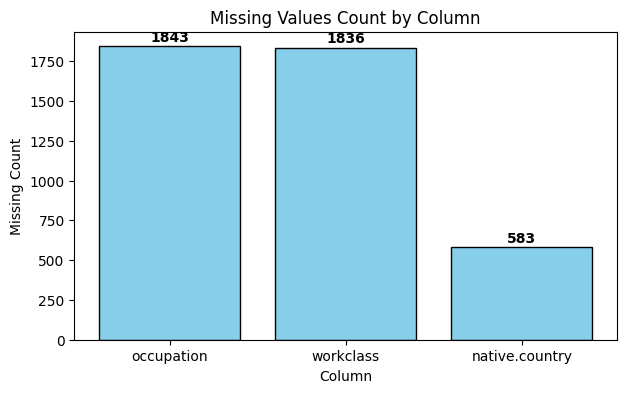

In [8]:
# Simple bar chart showing missing values
plt.figure(figsize=(7, 4))
plt.bar(missing_table.index, missing_table['Missing Count'], color='skyblue', edgecolor='black')
plt.title('Missing Values Count by Column')
plt.xlabel('Column')
plt.ylabel('Missing Count')

# Add the count on top of each bar
for i, count in enumerate(missing_table['Missing Count']):
    plt.text(i, count + 30, str(count), ha='center', fontweight='bold')

plt.show()


**What we observe:**
- **`occupation`**: 1,843 missing values (~5.66%)
- **`workclass`**: 1,836 missing values (~5.64%)
- **`native.country`**: 583 missing values (~1.79%)
- All other 12 columns have complete data (0 missing).


---
## Task 3 — Handle Missing Values & Justifications

Here are our decisions for handling the missing data:

1. **For `workclass` and `occupation` (Categorical/Text):**
   - **Decision:** Fill missing entries with `'Unknown'`.
   - **Why:** If we drop all rows with missing values, we would lose over 2,000 rows (around 7.4% of our entire dataset). Filling with `'Unknown'` keeps all rows while clearly showing that the person's job was not recorded.

2. **For `native.country` (Categorical/Text):**
   - **Decision:** Fill missing entries with `'Unknown'`.
   - **Why:** Most people in this dataset are from the US (~90%), but guessing someone's country might be incorrect. Marking it `'Unknown'` is simple and accurate.

3. **For Numeric Columns:**
   - **Check:** None of our numeric columns have missing data.
   - **Rule if needed:** For numeric columns with a normal bell curve, we use the **mean** (average). If the column has extreme outliers or is heavily skewed, we use the **median** (middle value).


In [9]:
# Fill missing text values with 'Unknown'
df['workclass'].fillna('Unknown', inplace=True)
df['occupation'].fillna('Unknown', inplace=True)
df['native.country'].fillna('Unknown', inplace=True)

# Confirm all missing values are handled
print("Total missing values left in dataset:", df.isnull().sum().sum())


Total missing values left in dataset: 0


C:\Users\Victus\AppData\Local\Temp\ipykernel_18728\435841540.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['workclass'].fillna('Unknown', inplace=True)
C:\Users\Victus\AppData\Local\Temp\ipykernel_18728\435841540.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exam

---
## Task 4 — Detect and Handle Duplicate Rows

Let's check if there are repeated rows in the dataset:
1. **Exact duplicates:** Rows where every single column is identical.
2. **Duplicates ignoring income:** Rows where all features are the same, but income might be different.


In [10]:
# 1. Check for exact duplicate rows
exact_dupes = df.duplicated().sum()
print("Number of exact duplicate rows:", exact_dupes)

# Let's view a few duplicate rows
print("Sample of duplicate rows:")
df[df.duplicated(keep=False)].head(6)


Number of exact duplicate rows: 24
Sample of duplicate rows:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
6227,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
7615,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
7978,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
8356,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
8453,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
8500,38,Private,207202,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,48,United-States,>50K


In [11]:
# 2. Check duplicates if we ignore the 'income' column
feature_columns = [col for col in df.columns if col != 'income']
dupes_no_income = df.duplicated(subset=feature_columns).sum()
print("Duplicate rows ignoring income:", dupes_no_income)


Duplicate rows ignoring income: 25


### Decision on Duplicates:
- **Exact Duplicates (24 rows):** These are identical across every single attribute, including income. They are redundant repeated entries, so we **drop them**.
- **Duplicates without income (25 rows):** The 1 extra row has identical demographics but different income. In real life, two people with the same age, education, and job can earn different incomes. We do not drop that row because it's valid data.


In [12]:
# Remove exact duplicate rows
print("Rows before dropping duplicates:", df.shape[0])
df.drop_duplicates(inplace=True)
print("Rows after dropping duplicates :", df.shape[0])


Rows before dropping duplicates: 32561
Rows after dropping duplicates : 32537


---
## Task 5 — Fix Inconsistent Categorical Data

In CSV datasets, text columns often have extra spaces at the beginning or end (e.g. `' Private'` instead of `'Private'`). 

Let's check unique values and use `.str.strip()` to remove leading and trailing spaces from all string columns.


In [13]:
# Check unique values in education and marital.status
print("Unique education values:")
print(df['education'].unique())

print("Unique marital.status values:")
print(df['marital.status'].unique())


Unique education values:
['HS-grad' 'Some-college' '7th-8th' '10th' 'Doctorate' 'Prof-school'
 'Bachelors' 'Masters' '11th' 'Assoc-acdm' 'Assoc-voc' '1st-4th' '5th-6th'
 '12th' '9th' 'Preschool']
Unique marital.status values:
['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']


In [14]:
# Strip extra spaces from all text columns
text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    df[col] = df[col].str.strip()

print("All extra spaces stripped from text columns successfully!")


All extra spaces stripped from text columns successfully!


---
## Task 6 — Descriptive Statistics (Mean vs. Median)

Let's look at the summary statistics for our numeric columns and compare the **mean** and **median** for `age` and `hours.per.week`.


In [15]:
# Summary statistics for numeric columns
print("Numeric Summary:")
df.describe()


Numeric Summary:


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,1.897808e+05,10.081815,1078.443741,87.368227,40.440329
std,13.637984,1.055565e+05,2.571633,7387.957424,403.101833,12.346889
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.369930e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [16]:
# Summary statistics for text columns
print("Categorical Summary:")
df.describe(include='object')


Categorical Summary:


,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,32537,32537,32537,32537,32537,32537,32537,32537,32537
unique,9,16,7,15,6,5,2,42,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22673,10494,14970,4136,13187,27795,21775,29153,24698


In [17]:
# Compare mean and median for age and hours worked
print("--- Age ---")
print("Mean Age   :", round(df['age'].mean(), 2))
print("Median Age :", round(df['age'].median(), 2))

print("--- Hours per Week ---")
print("Mean Hours   :", round(df['hours.per.week'].mean(), 2))
print("Median Hours :", round(df['hours.per.week'].median(), 2))


--- Age ---
Mean Age   : 38.59
Median Age : 37.0
--- Hours per Week ---
Mean Hours   : 40.44
Median Hours : 40.0


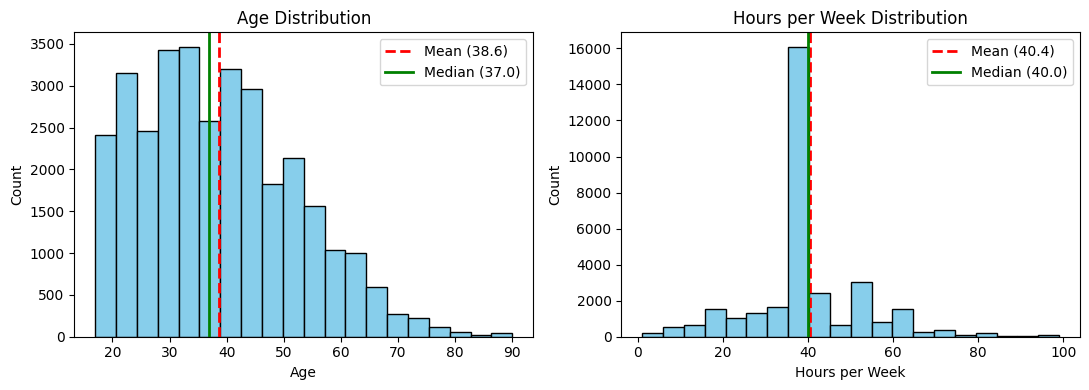

In [18]:
# Plot histograms for Age and Hours per Week
plt.figure(figsize=(11, 4))

# Age Histogram
plt.subplot(1, 2, 1)
plt.hist(df['age'], bins=20, color='skyblue', edgecolor='black')
plt.axvline(df['age'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean ({df['age'].mean():.1f})")
plt.axvline(df['age'].median(), color='green', linestyle='-', linewidth=2, label=f"Median ({df['age'].median():.1f})")
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend()

# Hours per Week Histogram
plt.subplot(1, 2, 2)
plt.hist(df['hours.per.week'], bins=20, color='skyblue', edgecolor='black')
plt.axvline(df['hours.per.week'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean ({df['hours.per.week'].mean():.1f})")
plt.axvline(df['hours.per.week'].median(), color='green', linestyle='-', linewidth=2, label=f"Median ({df['hours.per.week'].median():.1f})")
plt.title('Hours per Week Distribution')
plt.xlabel('Hours per Week')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()


### What the numbers tell us:
- **Age (Mean: 38.6, Median: 37.0):** The mean is a bit higher than the median because a few older people (up to age 90) pull the average slightly to the right.
- **Hours per Week (Mean: 40.4, Median: 40.0):** The mean and median are virtually identical because the vast majority of people work the standard 40 hours per week.


---
## Task 7 — Frequency Analysis

Let's find:
- **(a)** The most common occupation
- **(b)** The percentage distribution of `sex`
- **(c)** The percentage distribution of `income` (`<=50K` vs `>50K`) and whether it is balanced


In [19]:
# (a) Most common occupation
occupation_counts = df['occupation'].value_counts()
print("Top 5 Most Common Occupations:")
print(occupation_counts.head(5))

print(f"\n--> The most common occupation is: {occupation_counts.index[0]} ({occupation_counts.iloc[0]} people)")


Top 5 Most Common Occupations:
occupation
Prof-specialty     4136
Craft-repair       4094
Exec-managerial    4065
Adm-clerical       3768
Sales              3650
Name: count, dtype: int64

--> The most common occupation is: Prof-specialty (4136 people)


In [20]:
# (b) Percentage distribution of sex
sex_pct = df['sex'].value_counts(normalize=True) * 100
print("Sex Distribution (%):")
print(sex_pct.round(2))


Sex Distribution (%):
sex
Male      66.92
Female    33.08
Name: proportion, dtype: float64


In [21]:
# (c) Percentage distribution of income
income_pct = df['income'].value_counts(normalize=True) * 100
print("Income Label Distribution (%):")
print(income_pct.round(2))


Income Label Distribution (%):
income
<=50K    75.91
>50K     24.09
Name: proportion, dtype: float64


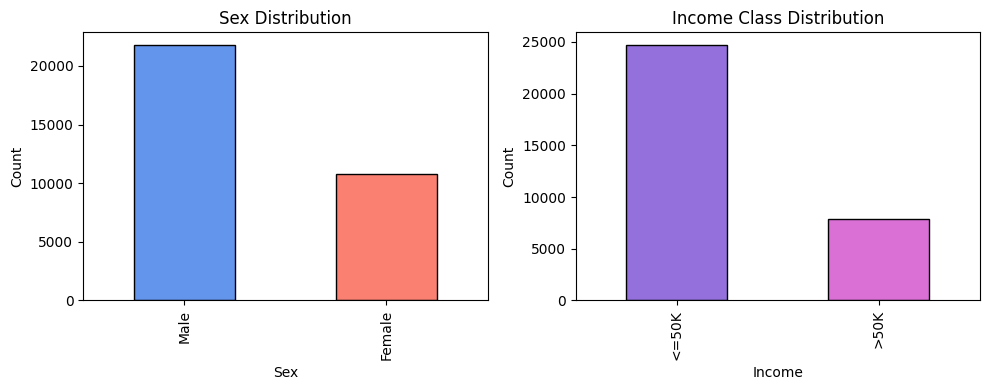

In [22]:
# Simple bar charts for sex and income distributions
plt.figure(figsize=(10, 4))

# Sex bar chart
plt.subplot(1, 2, 1)
df['sex'].value_counts().plot(kind='bar', color=['cornflowerblue', 'salmon'], edgecolor='black')
plt.title('Sex Distribution')
plt.xlabel('Sex')
plt.ylabel('Count')

# Income bar chart
plt.subplot(1, 2, 2)
df['income'].value_counts().plot(kind='bar', color=['mediumpurple', 'orchid'], edgecolor='black')
plt.title('Income Class Distribution')
plt.xlabel('Income')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


### Is the income class balanced?
- **`<=50K`**: ~75.9% (24,698 people)
- **`>50K`**: ~24.1% (7,839 people)
- **Conclusion:** No, the dataset is **imbalanced**. About 3 out of every 4 people earn `<=50K` (roughly a **3:1 ratio**).


---
## Task 8 — Cross-Check a Data Quality Assumption

We check if each `education` level title always corresponds to the exact same number in `education.num`.


In [23]:
# Check unique education.num for each education name
education_mapping = df.groupby('education')['education.num'].unique()
print("Education Level to Education Number Mapping:")
print(education_mapping)


Education Level to Education Number Mapping:
education
10th             [6]
11th             [7]
12th             [8]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
Assoc-acdm      [12]
Assoc-voc       [11]
Bachelors       [13]
Doctorate       [16]
HS-grad          [9]
Masters         [14]
Preschool        [1]
Prof-school     [15]
Some-college    [10]
Name: education.num, dtype: object


**Result:**
- Each education level has exactly **one** unique number (e.g. `Preschool` = 1, `HS-grad` = 9, `Bachelors` = 13, `Doctorate` = 16).
- There are **no inconsistencies** found. Both columns show the exact same information (one is text, one is a number).


---
## Task 9 — SQL-Based Data Extraction

Now we practice loading data into an in-memory SQLite database, running a SQL query, and loading the result back into pandas.


In [24]:
# 1. Create an in-memory SQLite database connection
conn = sqlite3.connect(':memory:')

# 2. Save our dataframe into a database table called 'adult_income'
df.to_sql('adult_income', conn, index=False, if_exists='replace')
print("Data loaded into SQLite table 'adult_income' successfully!")


Data loaded into SQLite table 'adult_income' successfully!


In [25]:
# 3. Write and run a SQL query: get all records where age > 30
query = 'SELECT * FROM adult_income WHERE age > 30'
df_sql = pd.read_sql_query(query, conn)

print("SQL Query Result Shape:", df_sql.shape)
print("First 3 rows from SQL query:")
df_sql.head(3)


SQL Query Result Shape: (21979, 15)
First 3 rows from SQL query:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Unknown,77053,HS-grad,9,Widowed,Unknown,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Unknown,186061,Some-college,10,Widowed,Unknown,Unmarried,Black,Female,0,4356,40,United-States,<=50K


In [26]:
# 4. Compare SQL result with pandas filtering to verify
pandas_count = len(df[df['age'] > 30])
sql_count = len(df_sql)

print("Rows returned by SQL query   :", sql_count)
print("Rows returned by Pandas filter:", pandas_count)

if sql_count == pandas_count:
    print("--> Verification Passed: Both SQL and Pandas return the exact same rows!")

# Close the database connection
conn.close()


Rows returned by SQL query   : 21979
Rows returned by Pandas filter: 21979
--> Verification Passed: Both SQL and Pandas return the exact same rows!


---
## Task 10 — Data Profiling Summary Report

### 1. Dataset Overview:
- **Dimensions:** 32,561 rows and 15 columns.
- **What it represents:** US Census data from 1994 with demographics, education, job details, and whether annual income is `<=50K` or `>50K`.

### 2. Data Quality Issues Found:
- **Hidden Missing Values:** Missing entries were stored as `'?'`. We found:
  - `occupation`: 1,843 missing rows (5.66%)
  - `workclass`: 1,836 missing rows (5.64%)
  - `native.country`: 583 missing rows (1.79%)
- **Duplicate Rows:** Found **24 exact duplicate rows**.
- **Inconsistent Text:** Extra leading and trailing spaces were present in text columns.

### 3. Key Observations:
- **Age:** Average age is ~38.6 years (median is 37).
- **Working Hours:** Most people work standard full-time (40 hours per week).
- **Top Occupations:** `Prof-specialty` and `Craft-repair` are the most common jobs.
- **Income Imbalance:** The target variable is imbalanced: **~75.9%** earn `<=50K` and **~24.1%** earn `>50K`.

### 4. Cleaning Decisions Made:
- **Missing Categorical Data:** Filled with `'Unknown'` to keep all records without making assumptions.
- **Duplicates:** Dropped the 24 exact duplicate rows using `df.drop_duplicates()`.
- **Whitespace:** Stripped extra spaces from all text columns using `.str.strip()`.


---
## Exporting the Cleaned Dataset
Finally, we save the cleaned DataFrame to `adult_cleaned.csv`.


In [27]:
# Save the cleaned dataset to CSV
df.to_csv('adult_cleaned.csv', index=False)
print("Cleaned dataset successfully saved to 'adult_cleaned.csv'!")
print(f"Final shape: {df.shape[0]} rows and {df.shape[1]} columns")


Cleaned dataset successfully saved to 'adult_cleaned.csv'!
Final shape: 32537 rows and 15 columns
